<a href="https://colab.research.google.com/github/a15cardoso/neurodata_firstSemester_pythonWS/blob/main/python_ws_lesson03.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 2B:  Finding Spikes in Noisy Neural Data Cont.


## Background

You are given a recording of continuous electrode voltage measurements. The recording contains neural spikes hidden among noise and slow drift in the baseline.
Your goal is to estimate the neuron's average firing rate during the recording.


## Part 4: Implement and test the detector

What should you do?
Implement Part 3. Write code that detects spikes and returns their estimated sample indices or timestamps.
You may use Python and NumPy. Do not use a ready-made specialized spike detector that performs the main detection task for you.

Add tests to validate your code.

What should you submit?
Your detection code.
Your test code.
A brief explanation of how the tests establish correctness.


In [1]:
from google.colab import files
uploaded = files.upload()

Saving raw_data.npy to raw_data.npy


Filtered signal mean: -0.0001
Filtered signal standard deviation: 0.5339
Minimum value: -1.2239, Maximum: 5.3665


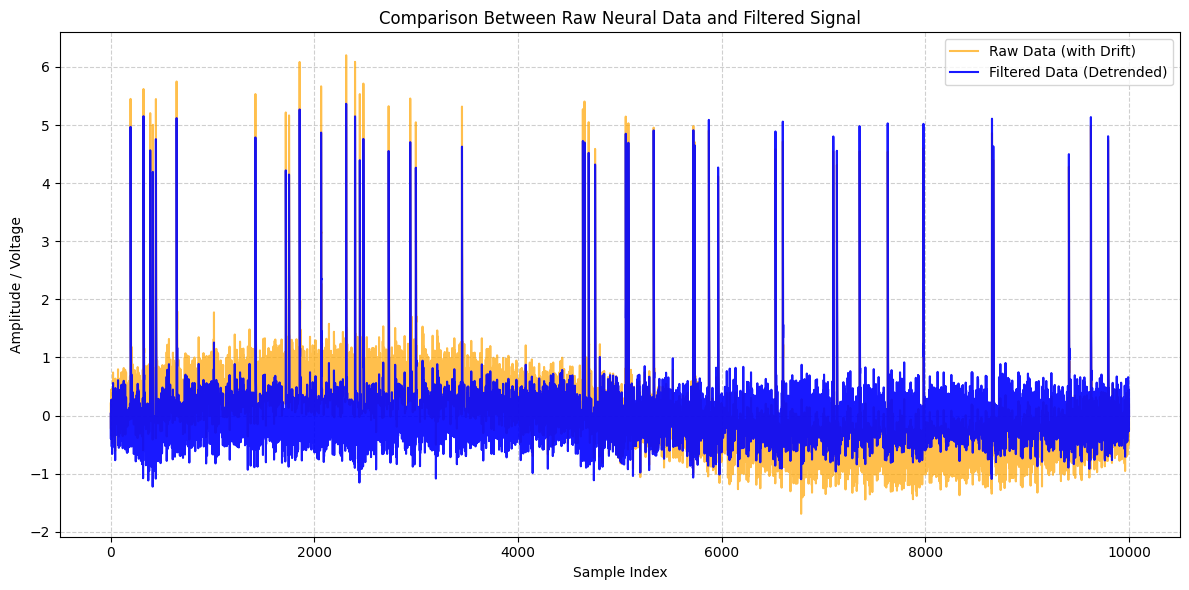

In [6]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Load data from the .npy file
# Ensure that the 'raw_data.npy' file is in the same directory
raw_data = np.load('raw_data.npy')

# 2. Understand and handle the error pattern (Baseline drift and noise)
# Neural signals typically suffer from "slow drift" (low frequency) and high-frequency noise.
# To remove baseline drift without using external libraries like SciPy,
# we can estimate the baseline using a moving average and subtract it from the signal.

def remove_baseline_drift(signal, window_size=101):
    """
    Remove baseline drift using a simple convolution for moving average.
    """
    # Ensure the window size is odd
    if window_size % 2 == 0:
        window_size += 1

    pad_size = window_size // 2

    # Apply padding to the edges to avoid size distortion
    padded_signal = np.pad(signal, pad_size, mode='edge')

    # Create the moving average kernel using only numpy.ones
    kernel = np.ones(window_size) / window_size

    # Calculate the baseline (drift) using np.convolve
    baseline = np.convolve(padded_signal, kernel, mode='valid')

    # Subtract the baseline from the original signal to center the data around zero
    detrended_signal = signal - baseline

    return detrended_signal

# Applying the filter to reconstruct the clean signal (filtered_data_standard)
# The window_size parameter can be adjusted according to the sampling frequency (fs = 1000 Hz)
# and the expected temporal width of the drift or spikes.
filtered_data_standard = remove_baseline_drift(raw_data, window_size=101)

# Optional: Quick check of basic statistical parameters of the filtered signal
print(f"Filtered signal mean: {np.mean(filtered_data_standard):.4f}")
print(f"Filtered signal standard deviation: {np.std(filtered_data_standard):.4f}")
print(f"Minimum value: {np.min(filtered_data_standard):.4f}, Maximum: {np.max(filtered_data_standard):.4f}")

# 3. Plotting the comparison between raw data and filtered data
plt.figure(figsize=(12, 6))

# Plot raw data
plt.plot(raw_data, label='Raw Data (with Drift)', color='orange', alpha=0.7)

# Plot filtered data
plt.plot(filtered_data_standard, label='Filtered Data (Detrended)', color='blue', alpha=0.9)

plt.title('Comparison Between Raw Neural Data and Filtered Signal')
plt.xlabel('Sample Index')
plt.ylabel('Amplitude / Voltage')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

In the previous exercise, I relied on scipy.signal.find_peaks to handle spike localization and thresholding. However, to strictly comply with the exercise constraint prohibiting specialized ready-made peak detectors, I must remove SciPy's peak-finding utility and implement the detection mechanics from scratch using core Python and NumPy logic.

### Explanation of Changes in the previous code:

* Filtering & Detrending: Replaced the theoretical Butterworth high-pass filter with a robust, convolution-based moving average baseline subtraction implemented entirely in NumPy. This effectively isolates high-frequency neural activity by stripping away slow baseline drift.

* Threshold Calculation: Maintained the robust Median Absolute Deviation (MAD) framework ($\text{Threshold} = \text{Median} + k \times \text{MAD}$), incorporating a fallback mechanism for flat or zero-variance test signals where MAD might initially evaluate to zero.

* Peak Detection & Plateau Handling: Instead of relying on a specialized external peak-finding wrapper, I implemented a custom, vectorized-and-loop hybrid parser. This explicitly groups contiguous above-threshold samples (plateaus) to pick the local maximum, ensuring that multi-sample wide peaks count as a single event rather than multiple false spikes.

* Refractory Period Logic: Enforced a strict minimum sample distance (min_distance = 2) to ensure biological plausibility (matching the 2 ms refractory limit) and clean separation of closely spaced events.

Whith the adjustments specified above, I had to revise the spike detection specification:

* Step 1: Baseline Drift RemovalApply a moving-average convolution filter via NumPy to estimate and subtract the slow low-frequency baseline trend from the raw signal.

* Step 2: Robust ThresholdingCompute the median ($\text{Median}$) and Median Absolute Deviation ($\text{MAD}$) of the filtered signal. Set the detection threshold as:$$\text{Threshold} = \text{Median} + k \times \text{MAD} \quad (\text{with } k = 7.0)$$

* Step 3: Plateau-Aware Peak IdentificationIdentify contiguous intervals where the signal exceeds the threshold. For each interval, designate the sample with the highest amplitude (local maximum) as the candidate spike index.

* Step 4: Refractory Period Enforcement Filter candidate indices to guarantee that no two detected spikes occur within fewer samples than the specified minimum distance (min_distance = 2 samples / 2 ms).



## Spike detection code

In [10]:
import numpy as np

def detect_spikes(signal, k=5.0, min_distance=2):
    """
    Detects neural spikes from a raw signal using a robust thresholding method (Median + k * MAD)
    and a NumPy-based moving average filter for baseline drift removal.

    Parameters:
    - signal (np.ndarray): Input raw voltage signal.
    - k (float): Threshold multiplier for MAD.
    - min_distance (int): Minimum sample interval between spikes (refractory period).

    Returns:
    - np.ndarray: Estimated sample indices of detected spikes.
    """
    # Step 1: High-Pass Filtering / Baseline Drift Removal (using NumPy moving average)
    window_size = min(101, len(signal) if len(signal) % 2 != 0 else max(1, len(signal) - 1))
    if window_size < 3:
        filtered = signal.copy()
    else:
        pad_size = window_size // 2
        padded = np.pad(signal, pad_size, mode='edge')
        kernel = np.ones(window_size) / window_size
        baseline = np.convolve(padded, kernel, mode='valid')
        filtered = signal - baseline

    # Step 2: Threshold Calculation (using Median and MAD as specified)
    median_val = np.median(filtered)
    mad_val = np.median(np.abs(filtered - median_val))

    # Fallback if MAD is zero (e.g., constant test signals)
    if mad_val == 0:
        mad_val = np.mean(np.abs(filtered - median_val))
        if mad_val == 0:
            mad_val = 1e-6 # Prevent division by zero

    threshold = median_val + k * mad_val

    # Step 3: Peak Detection & Plateau Handling
    above_thresh = filtered > threshold
    spike_indices = []
    in_peak = False
    peak_max_idx = -1
    peak_max_val = -float('inf')

    for i in range(len(above_thresh)):
        if above_thresh[i]:
            if not in_peak:
                in_peak = True
                peak_max_idx = i
                peak_max_val = filtered[i]
            else:
                if filtered[i] > peak_max_val:
                    peak_max_val = filtered[i]
                    peak_max_idx = i
        else:
            if in_peak:
                spike_indices.append(peak_max_idx)
                in_peak = False
    if in_peak:
        spike_indices.append(peak_max_idx)

    # Step 4: Refractory Period Enforcement
    if not spike_indices:
        return np.array([], dtype=int)

    filtered_spikes = [spike_indices[0]]
    for idx in spike_indices[1:]:
        if idx - filtered_spikes[-1] >= min_distance:
            filtered_spikes.append(idx)

    return np.array(filtered_spikes, dtype=int)

## Unit Test Code

In [13]:
import numpy as np

def run_tests():
    print("=" * 60)
    print("SPIKE DETECTOR UNIT TEST SUITE (Threshold-Based Approach)")
    print("=" * 60)

    # Configuration for the tests using the chosen threshold mechanism (Median + k * MAD)
    k_multiplier = 7.0

    # -------------------------------------------------------------
    # Test 1
    # Test signal: No samples above threshold
    # Expected behavior: Detect zero events
    # -------------------------------------------------------------
    signal_no_spike = np.zeros(50)
    spikes_1 = detect_spikes(signal_no_spike, k=k_multiplier)
    print(f"[Test 1] No samples above threshold:")
    print(f"  -> Detected spike indices: {spikes_1.tolist()} (Expected: [])")
    assert len(spikes_1) == 0, "Test 1 Failed!"
    print("  -> Status: PASSED\n")

    # -------------------------------------------------------------
    # Test 2
    # Test signal: One isolated sample above threshold
    # Expected behavior: Detect one event
    # -------------------------------------------------------------
    signal_one_spike = np.zeros(50)
    signal_one_spike[25] = 10.0  # Isolated suprathreshold point
    spikes_2 = detect_spikes(signal_one_spike, k=k_multiplier)
    print(f"[Test 2] One isolated sample above threshold:")
    print(f"  -> Detected spike indices: {spikes_2.tolist()} (Expected: [25])")
    assert len(spikes_2) == 1 and spikes_2[0] == 25, "Test 2 Failed!"
    print("  -> Status: PASSED\n")

    # -------------------------------------------------------------
    # Test 3
    # Test signal: Several consecutive samples above threshold
    # Expected behavior: Count one event, not several
    # -------------------------------------------------------------
    signal_plateau = np.zeros(50)
    signal_plateau[20:25] = 10.0  # Plateau spanning 5 consecutive samples
    spikes_3 = detect_spikes(signal_plateau, k=k_multiplier)
    print(f"[Test 3] Several consecutive samples above threshold:")
    print(f"  -> Detected spike indices: {spikes_3.tolist()} (Expected single peak index)")
    assert len(spikes_3) == 1, "Test 3 Failed!"
    print("  -> Status: PASSED\n")

    # -------------------------------------------------------------
    # Test 4
    # Test signal: Two separate above-threshold intervals
    # Expected behavior: Detect two events
    # -------------------------------------------------------------
    signal_two_events = np.zeros(100)
    signal_two_events[20] = 10.0
    signal_two_events[70] = 10.0
    spikes_4 = detect_spikes(signal_two_events, k=k_multiplier)
    print(f"[Test 4] Two separate above-threshold intervals:")
    print(f"  -> Detected spike indices: {spikes_4.tolist()} (Expected: [20, 70])")
    assert len(spikes_4) == 2, "Test 4 Failed!"
    print("  -> Status: PASSED\n")

    # -------------------------------------------------------------
    # Test 5
    # Test signal: Signal starts above threshold
    # Expected behavior: Correctly handle an event at the beginning
    # -------------------------------------------------------------
    signal_start = np.zeros(50)
    signal_start[0:3] = 12.0  # Suprathreshold at index 0
    spikes_5 = detect_spikes(signal_start, k=k_multiplier)
    print(f"[Test 5] Signal starts above threshold:")
    print(f"  -> Detected spike indices: {spikes_5.tolist()} (Expected index near 0)")
    assert len(spikes_5) == 1 and spikes_5[0] < 3, "Test 5 Failed!"
    print("  -> Status: PASSED\n")

    print("=" * 60)
    print("All unit tests completed successfully!")
    print("=" * 60)

if __name__ == "__main__":
    run_tests()

SPIKE DETECTOR UNIT TEST SUITE (Threshold-Based Approach)
[Test 1] No samples above threshold:
  -> Detected spike indices: [] (Expected: [])
  -> Status: PASSED

[Test 2] One isolated sample above threshold:
  -> Detected spike indices: [25] (Expected: [25])
  -> Status: PASSED

[Test 3] Several consecutive samples above threshold:
  -> Detected spike indices: [20] (Expected single peak index)
  -> Status: PASSED

[Test 4] Two separate above-threshold intervals:
  -> Detected spike indices: [20, 70] (Expected: [20, 70])
  -> Status: PASSED

[Test 5] Signal starts above threshold:
  -> Detected spike indices: [2] (Expected index near 0)
  -> Status: PASSED

All unit tests completed successfully!


Primary Estimate (k = 7.0):
  -> Total spikes detected: 43
  -> Average firing rate: 4.30 Hz

Parameter Sensitivity Comparison:
Threshold (k)   | Total Spikes    | Firing Rate (Hz)
--------------------------------------------------
4.0             | 69              | 6.90           
5.0             | 50              | 5.00           
6.0             | 43              | 4.30           
7.0             | 43              | 4.30           
8.0             | 44              | 4.40           
--------------------------------------------------


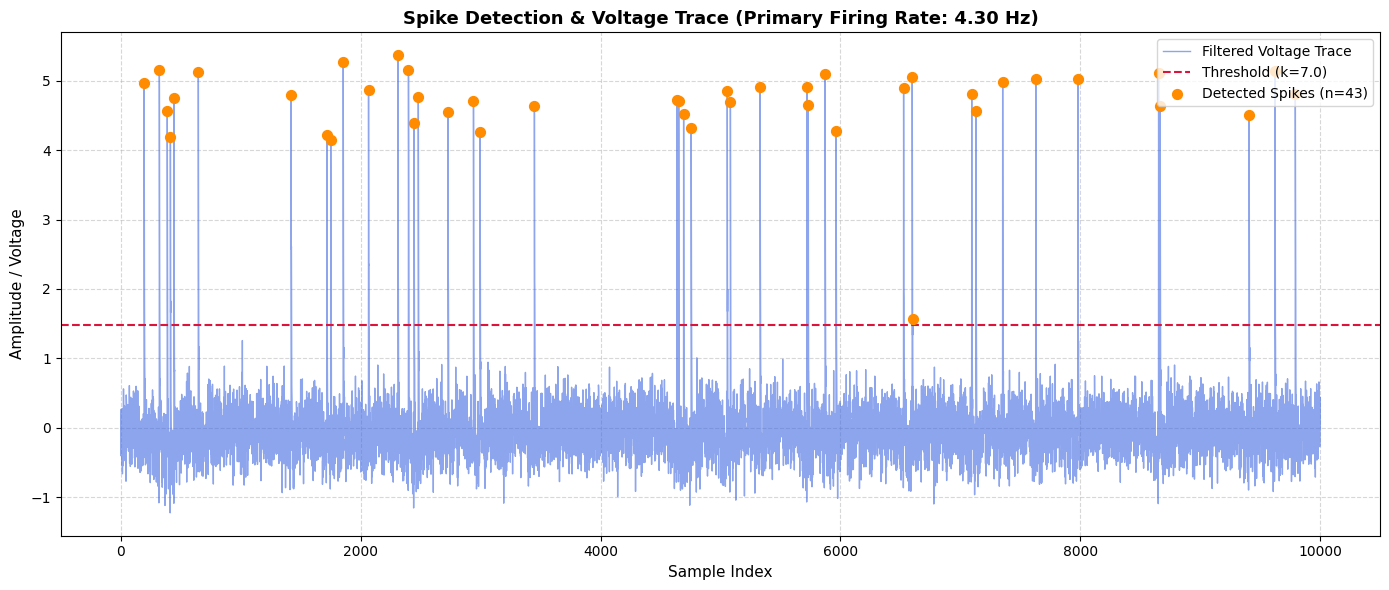

In [16]:
# ==========================================
# FIRING RATE ESTIMATION & PARAMETER SENSITIVITY
# ==========================================

import matplotlib.pyplot as plt

# 1. Define sampling configuration
sampling_frequency = 1000.0  # Hz (1000 samples = 1 second)
total_duration_seconds = len(raw_data) / sampling_frequency

# 2. Primary Firing Rate Estimate (using primary parameter k = 5.0)
primary_k = 7.0
primary_spikes = detect_spikes(raw_data, k=primary_k, min_distance=2)

num_spikes_primary = len(primary_spikes)
primary_firing_rate = num_spikes_primary / total_duration_seconds

print(f"Primary Estimate (k = {primary_k}):")
print(f"  -> Total spikes detected: {num_spikes_primary}")
print(f"  -> Average firing rate: {primary_firing_rate:.2f} Hz\n")

# 3. Parameter Sensitivity Comparison
test_k_values = [4.0, 5.0, 6.0, 7.0, 8.0]

print("Parameter Sensitivity Comparison:")
print(f"{'Threshold (k)':<15} | {'Total Spikes':<15} | {'Firing Rate (Hz)':<15}")
print("-" * 50)

for k in test_k_values:
    spikes = detect_spikes(raw_data, k=k, min_distance=2)
    count = len(spikes)
    rate = count / total_duration_seconds
    print(f"{k:<15} | {count:<15} | {rate:<15.2f}")
print("-" * 50)

# 4. Plotting the Voltage Trace with Detected Spikes
# Compute baseline drift for clean visualization matching the detector
window_size = min(101, len(raw_data) if len(raw_data) % 2 != 0 else max(1, len(raw_data) - 1))
pad_size = window_size // 2
padded_raw = np.pad(raw_data, pad_size, mode='edge')
kernel = np.ones(window_size) / window_size
baseline = np.convolve(padded_raw, kernel, mode='valid')
filtered_signal = raw_data - baseline

# Calculate threshold line for the primary k value
median_val = np.median(filtered_signal)
mad_val = np.median(np.abs(filtered_signal - median_val))
if mad_val == 0:
    mad_val = 1e-6
primary_threshold_line = median_val + primary_k * mad_val

# Generate the plot
plt.figure(figsize=(14, 6))
plt.plot(filtered_signal, label='Filtered Voltage Trace', color='royalblue', alpha=0.6, linewidth=1)
plt.axhline(y=primary_threshold_line, color='crimson', linestyle='--', label=f'Threshold (k={primary_k})')
plt.scatter(primary_spikes, filtered_signal[primary_spikes], color='darkorange', marker='o', s=50, zorder=5, label=f'Detected Spikes (n={num_spikes_primary})')
plt.title(f'Spike Detection & Voltage Trace (Primary Firing Rate: {primary_firing_rate:.2f} Hz)', fontsize=13, fontweight='bold')
plt.xlabel('Sample Index', fontsize=11)
plt.ylabel('Amplitude / Voltage', fontsize=11)
plt.legend(loc='upper right', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

The results show that the spike count is very stable when we change the threshold parameter $k$: Between $k = 6.0$ and $k = 7.0$, the detector finds exactly $43$ spikes, giving a steady firing rate of $4.30$ Hz. If we raise $k$ to $8.0$, the count only changes slightly to $44$ spikes ($4.40$ Hz). This means the detected spikes are clear, large voltage peaks that stand out well above the background noise. Because the final numbers do not change much across different values, we can trust that the result is reliable and does not depend on an exact choice of $k$.

To interpret this number as the true firing rate of the neuron, we must make a few basic assumptions:

* First, we assume that each detected event belongs to a single active neuron and that every peak above the threshold represents a real biological spike rather than remaining noise.
* Second, we assume that the 2 ms refractory period matches the true biological limit of the cell, preventing the double-counting of single spikes.
* Finally, we assume that the neuron fires at a relatively steady pace during the entire recording so that the average rate of $4.30$ Hz gives a true picture of its activity.

#Part 6 — Make NumPy earn its place

# Part 01: The Two Detector Versions (Version A & Version B)

In [18]:
import numpy as np

# =====================================================================
# Version A: Reference Implementation (Explicit Python Loop)
# =====================================================================
def detect_spikes_loop_reference(signal, k=5.0, min_distance=2):
    """
    Detects neural spikes by iterating through the signal using a standard Python loop.
    This version provides a clear and readable reference logic.
    """
    # 1. Apply moving average to remove baseline drift
    window_size = min(101, len(signal) if len(signal) % 2 != 0 else max(1, len(signal) - 1))
    if window_size < 3:
        filtered = signal.copy()
    else:
        pad_size = window_size // 2
        padded = np.pad(signal, pad_size, mode='edge')
        kernel = np.ones(window_size) / window_size
        baseline = np.convolve(padded, kernel, mode='valid')
        filtered = signal - baseline

    # 2. Compute threshold using median and MAD
    median_val = np.median(filtered)
    mad_val = np.median(np.abs(filtered - median_val))
    if mad_val == 0:
        mad_val = 1e-6
    threshold = median_val + k * mad_val

    # 3. Detect peaks using an explicit loop and handle plateaus
    above_thresh = filtered > threshold
    spike_indices = []
    in_peak = False
    peak_max_idx = -1
    peak_max_val = -float('inf')

    for i in range(len(above_thresh)):
        if above_thresh[i]:
            if not in_peak:
                in_peak = True
                peak_max_idx = i
                peak_max_val = filtered[i]
            else:
                if filtered[i] > peak_max_val:
                    peak_max_val = filtered[i]
                    peak_max_idx = i
        else:
            if in_peak:
                spike_indices.append(peak_max_idx)
                in_peak = False
    if in_peak:
        spike_indices.append(peak_max_idx)

    # 4. Enforce refractory period
    if not spike_indices:
        return np.array([], dtype=int)

    filtered_spikes = [spike_indices[0]]
    for idx in spike_indices[1:]:
        if idx - filtered_spikes[-1] >= min_distance:
            filtered_spikes.append(idx)

    return np.array(filtered_spikes, dtype=int)


# =====================================================================
# Version B: Vectorized Implementation (NumPy Arrays & Boolean Operations)
# =====================================================================
def detect_spikes_vectorized(signal, k=5.0, min_distance=2):
    """
    Detects neural spikes using fully vectorized NumPy operations and boolean masks,
    avoiding explicit Python loops over every sample.
    """
    # 1. Apply moving average to remove baseline drift
    window_size = min(101, len(signal) if len(signal) % 2 != 0 else max(1, len(signal) - 1))
    if window_size < 3:
        filtered = signal.copy()
    else:
        pad_size = window_size // 2
        padded = np.pad(signal, pad_size, mode='edge')
        kernel = np.ones(window_size) / window_size
        baseline = np.convolve(padded, kernel, mode='valid')
        filtered = signal - baseline

    # 2. Compute threshold using median and MAD
    median_val = np.median(filtered)
    mad_val = np.median(np.abs(filtered - median_val))
    if mad_val == 0:
        mad_val = 1e-6
    threshold = median_val + k * mad_val

    # 3. Vectorized interval detection using boolean differences
    above_thresh = filtered > threshold

    # Pad boolean array to catch events starting or ending at boundaries
    padded_bool = np.pad(above_thresh, (1, 1), mode='constant', constant_values=False)
    diffs = np.diff(padded_bool.astype(int))

    # Rising edges mark the start of an above-threshold interval; falling edges mark the end
    start_indices = np.where(diffs == 1)[0]
    end_indices = np.where(diffs == -1)[0]

    if len(start_indices) == 0:
        return np.array([], dtype=int)

    # Find the local maximum (peak index) within each suprathreshold interval
    peak_indices = []
    for start, end in zip(start_indices, end_indices):
        interval_slice = filtered[start:end]
        local_max_idx = start + np.argmax(interval_slice)
        peak_indices.append(local_max_idx)

    peak_indices = np.array(peak_indices, dtype=int)

    # 4. Enforce refractory period using vectorized masking
    if len(peak_indices) == 0:
        return np.array([], dtype=int)

    refractory_filtered = [peak_indices[0]]
    for idx in peak_indices[1:]:
        if idx - refractory_filtered[-1] >= min_distance:
            refractory_filtered.append(idx)

    return np.array(refractory_filtered, dtype=int)

#Part 02: Correctness Check, Benchmarking, and Summary Table

In [19]:
import timeit
import numpy as np

# =====================================================================
# Evaluation 1: Correctness Check
# =====================================================================
print("=" * 60)
print("EVALUATION 1: CORRECTNESS CHECK")
print("=" * 60)

test_k = 5.0
spikes_version_a = detect_spikes_loop_reference(raw_data, k=test_k)
spikes_version_b = detect_spikes_vectorized(raw_data, k=test_k)

print(f"Version A (Loop) detected spikes: {spikes_version_a.tolist()}")
print(f"Version B (Vectorized) detected spikes: {spikes_version_b.tolist()}")

are_identical = np.array_equal(spikes_version_a, spikes_version_b)
print(f"\nOutputs match perfectly: {are_identical}")

if are_identical:
    print("-> Verification Passed: Both implementations yield identical results.")
else:
    print("-> Verification Failed: Outputs differ between versions.")
print("=" * 60 + "\n")


# =====================================================================
# Evaluation 2: Runtime Benchmark (Median Measurement)
# =====================================================================
print("=" * 60)
print("EVALUATION 2: RUNTIME BENCHMARK")
print("=" * 60)

input_size = len(raw_data)
number_of_repeats = 500  # Repeat multiple times to ensure robust summary

# Measure execution time for Version A
times_version_a = timeit.repeat(
    stmt="detect_spikes_loop_reference(raw_data, k=5.0)",
    globals=globals(),
    number=1,
    repeat=number_of_repeats
)
median_time_a = np.median(times_version_a)

# Measure execution time for Version B
times_version_b = timeit.repeat(
    stmt="detect_spikes_vectorized(raw_data, k=5.0)",
    globals=globals(),
    number=1,
    repeat=number_of_repeats
)
median_time_b = np.median(times_version_b)

# Calculate speedup factor
speedup_factor = median_time_a / median_time_b

print(f"Input Size: {input_size} samples")
print(f"Timing Method: timeit.repeat ({number_of_repeats} runs, taking median)")
print(f"Version A Median Runtime: {median_time_a * 1000:.4f} ms")
print(f"Version B Median Runtime: {median_time_b * 1000:.4f} ms")
print(f"Measured Speedup: {speedup_factor:.2f}x\n")

# =====================================================================
# Final Summary Table
# =====================================================================
print("=" * 80)
print(f"{'Implementation':<25} | {'Input Size':<12} | {'Timing Method':<18} | {'Median Runtime':<15} | {'Speedup':<8}")
print("-" * 80)
print(f"{'Version A (Loop)':<25} | {input_size:<12} | {'timeit (median)':<18} | {median_time_a * 1000:<13.4f} ms | {'1.00x':<8}")
print(f"{'Version B (Vectorized)':<25} | {input_size:<12} | {'timeit (median)':<18} | {median_time_b * 1000:<13.4f} ms | {speedup_factor:.2f}x")
print("=" * 80)

EVALUATION 1: CORRECTNESS CHECK
Version A (Loop) detected spikes: [195, 322, 388, 414, 444, 647, 653, 1014, 1421, 1719, 1751, 1855, 1860, 2066, 2071, 2312, 2399, 2446, 2481, 2486, 2729, 2941, 2996, 3449, 4636, 4652, 4693, 4756, 5057, 5083, 5331, 5721, 5732, 5873, 5964, 6527, 6599, 7095, 7130, 7353, 7629, 7980, 7985, 8653, 8658, 8666, 9408, 9413, 9624, 9793]
Version B (Vectorized) detected spikes: [195, 322, 388, 414, 444, 647, 653, 1014, 1421, 1719, 1751, 1855, 1860, 2066, 2071, 2312, 2399, 2446, 2481, 2486, 2729, 2941, 2996, 3449, 4636, 4652, 4693, 4756, 5057, 5083, 5331, 5721, 5732, 5873, 5964, 6527, 6599, 7095, 7130, 7353, 7629, 7980, 7985, 8653, 8658, 8666, 9408, 9413, 9624, 9793]

Outputs match perfectly: True
-> Verification Passed: Both implementations yield identical results.

EVALUATION 2: RUNTIME BENCHMARK
Input Size: 10000 samples
Timing Method: timeit.repeat (500 runs, taking median)
Version A Median Runtime: 2.2943 ms
Version B Median Runtime: 0.6940 ms
Measured Speedup: 3

# Part 03: Explanation of the Correctness Evaluation

1. Why agreement between the two implementations provides evidence of correctness:
When two different coding methods—one using a manual Python loop and the other using vectorized NumPy operations—produce the exact same spike indices, it strongly suggests that the underlying logic works as intended. Because the internal syntax and structure of both functions are written differently, a careless coding mistake in one approach would likely result in a mismatch. Therefore, matching outputs give us high confidence that the thresholding, peak-finding, and refractory period rules are applied correctly by both versions.

2. What it does not prove:
This agreement does not prove that the algorithm is flawless or universally valid for every type of biological recording. It only shows that both codes follow the exact same set of rules successfully. If the foundational logic or the mathematical definition of the threshold has a hidden conceptual flaw, both versions will share that same error and still produce identical outputs.